# 12 · Live forecasting prototype

The end-to-end loop that became the dashboard: pull the live feed → validate → fetch the 7-day GFS forecast → call the deployed model → archive the forecast → score it once actuals arrive.

**Key results**
- Live feed matches the training data exactly on 2,123 overlapping days; publication lag ≈ 1 day.
- First archived live forecast: origin 2026-11-19 (`data/forecasts/`).

> Paths are relative to `notebooks/`. Outputs are from the original research run; see [`data/README.md`](../data/README.md) for data that must be downloaded.

## 1. Pull the live Grid-Sentinel feed

In [1]:
import pandas as pd
import requests
from io import StringIO

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "Deducinnamoroll/Grid-Sentinel/main/"
    "Dataset/study3_states.csv"
)

response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

live_data = pd.read_csv(StringIO(response.text))

print("Shape:", live_data.shape)
print("\nColumns:", live_data.columns.tolist())
print("\nSample:")
display(live_data.head(3))

Shape: (104580, 11)

Columns: ['date', 'region', 'state', 'max_demand_met_mw', 'shortage_max_demand_mw', 'energy_met_mu', 'drawal_schedule_mu', 'od_ud_mu', 'max_od_mw', 'energy_shortage_mu', 'max_ace_mw']

Sample:


,date,region,state,max_demand_met_mw,shortage_max_demand_mw,energy_met_mu,drawal_schedule_mu,od_ud_mu,max_od_mw,energy_shortage_mu,max_ace_mw
0,2018-12-31,ER,Bihar,4362.0,0.0,76.8,70.7,0.7,460.0,0.0,NaN
1,2018-12-31,ER,DVC,3123.0,0.0,65.3,-31.4,2.2,396.0,0.0,NaN
2,2018-12-31,ER,Jharkhand,1199.0,0.0,26.1,19.0,0.8,169.0,0.0,NaN


## 2. Extract Delhi and check completeness

In [2]:
delhi = live_data.loc[
    live_data["state"].str.strip().str.casefold() == "delhi",
    ["date", "energy_met_mu"]
].copy()

delhi["date"] = pd.to_datetime(delhi["date"])
delhi["energy_met_mu"] = pd.to_numeric(
    delhi["energy_met_mu"], errors="coerce"
)

delhi = delhi.sort_values("date").reset_index(drop=True)

print("Delhi rows:", len(delhi))
print("Date range:", delhi.date.min(), "to", delhi.date.max())
print("Missing values:", delhi.energy_met_mu.isna().sum())
print("Duplicate dates:", delhi.date.duplicated().sum())

recent = delhi.tail(56)

print("\nLatest 56 observations:")
print("From:", recent.date.min().date())
print("To:", recent.date.max().date())

print("Consecutive dates:",
      recent.date.diff().dropna().eq(pd.Timedelta(days=1)).all())

display(recent.tail(7))

Delhi rows: 2811
Date range: 2018-12-31 00:00:00 to 2026-11-19 00:00:00
Missing values: 0
Duplicate dates: 0

Latest 56 observations:
From: 2026-09-25
To: 2026-11-19
Consecutive dates: True


,date,energy_met_mu
2804,2026-11-13,83.82
2805,2026-11-14,79.90
2806,2026-11-15,74.85
2807,2026-11-16,78.75
2808,2026-11-17,78.62
2809,2026-11-18,78.90
2810,2026-11-19,77.67


## 3. Confirm the live feed matches the training data

In [3]:
historical = pd.read_csv(
    "../data/processed/gridpulse_v2_development.csv"
)

print("Historical columns:", historical.columns.tolist())
display(historical.head(2))

Historical columns: ['date', 'energy_met_mu', 'max_demand_met_mw', 'energy_missing']


,date,energy_met_mu,max_demand_met_mw,energy_missing
0,2018-12-31,69.0,4292.0,False
1,2019-01-01,69.6,4336.0,False


In [4]:
historical["date"] = pd.to_datetime(historical["date"])

comparison = historical.loc[
    ~historical["energy_missing"],
    ["date", "energy_met_mu"]
].merge(
    delhi[["date", "energy_met_mu"]],
    on="date",
    suffixes=("_training", "_live")
)

comparison["abs_diff"] = (
    comparison["energy_met_mu_training"]
    - comparison["energy_met_mu_live"]
).abs()

print("Overlapping observations:", len(comparison))
print("Mean absolute difference:", comparison["abs_diff"].mean())
print("Maximum difference:", comparison["abs_diff"].max())
print("Exact matches (%):", 100 * (comparison["abs_diff"] < 1e-6).mean())

display(comparison.nlargest(5, "abs_diff"))

Overlapping observations: 2123
Mean absolute difference: 0.0
Maximum difference: 0.0
Exact matches (%): 100.0


,date,energy_met_mu_training,energy_met_mu_live,abs_diff
0,2018-12-31,69.0,69.0,0.0
1,2019-01-01,69.6,69.6,0.0
2,2019-01-02,69.0,69.0,0.0
3,2019-01-03,68.3,68.3,0.0
4,2019-01-04,73.9,73.9,0.0


## 4. Take the latest 56 days as model history

In [5]:
import pandas as pd
import numpy as np

delhi = delhi.sort_values("date").reset_index(drop=True)

recent = delhi.tail(56).copy()

assert len(recent) == 56
assert recent["energy_met_mu"].notna().all()
assert recent["date"].is_unique
assert recent["date"].diff().dropna().eq(
    pd.Timedelta(days=1)
).all(), "Demand history contains missing dates"

forecast_origin = recent["date"].max()
demand_history = recent["energy_met_mu"].astype(float).tolist()

print("Latest available observation:", forecast_origin.date())
print("Forecast starts:", (forecast_origin + pd.Timedelta(days=1)).date())
print("History length:", len(demand_history))
print("Demand range:", min(demand_history), "to", max(demand_history), "MU")
print("Data lag:", (pd.Timestamp.today().normalize() - forecast_origin).days, "days")

Latest available observation: 2026-11-19
Forecast starts: 2026-11-20
History length: 56
Demand range: 70.29 to 136.57 MU
Data lag: 1 days


## 5. Fetch the 7-day GFS temperature forecast (Open-Meteo)

In [6]:
import requests
import pandas as pd

forecast_dates = pd.date_range(
    forecast_origin + pd.Timedelta(days=1),
    periods=7,
    freq="D",
)

params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "daily": (
        "temperature_2m_mean,"
        "temperature_2m_max,"
        "temperature_2m_min"
    ),
    "timezone": "Asia/Kolkata",
    "start_date": forecast_dates[0].strftime("%Y-%m-%d"),
    "end_date": forecast_dates[-1].strftime("%Y-%m-%d"),
}

response = requests.get(
    "https://api.open-meteo.com/v1/gfs",
    params=params,
    timeout=60,
)
response.raise_for_status()

daily = response.json()["daily"]

weather_forecast = [
    {
        "date": date,
        "mean": mean,
        "max": maximum,
        "min": minimum,
    }
    for date, mean, maximum, minimum in zip(
        daily["time"],
        daily["temperature_2m_mean"],
        daily["temperature_2m_max"],
        daily["temperature_2m_min"],
    )
]

assert [r["date"] for r in weather_forecast] == [
    d.strftime("%Y-%m-%d") for d in forecast_dates
], "Weather dates do not match the forecast horizon"

assert len(weather_forecast) == 7
assert all(
    all(r[k] is not None for k in ("mean", "max", "min"))
    for r in weather_forecast
)

display(pd.DataFrame(weather_forecast))

,date,mean,max,min
0,2026-11-20,23.8,27.2,20.5
1,2026-11-21,24.0,27.3,20.8
2,2026-11-22,24.4,27.2,21.2
3,2026-11-23,24.4,28.1,21.0
4,2026-11-24,24.0,28.4,20.1
5,2026-11-25,24.0,27.5,20.6
6,2026-11-26,24.2,27.8,20.9


## 6. Call the deployed model through the authenticated client

In [8]:
import sys
from pathlib import Path
import pandas as pd
from datetime import datetime, timezone

sys.path.insert(0, str(Path("../src/gridpulse").resolve()))

from gridpulse_client import GridPulseClient

client = GridPulseClient()

issued_at = datetime.now(timezone.utc)

live_result = client.predict(
    forecast_origin=forecast_origin.date().isoformat(),
    demand_history_mu=demand_history,
    weather_forecast=weather_forecast,
)

forecast_df = pd.DataFrame(live_result["predictions"])

print("Forecast generated (UTC):", issued_at.isoformat())
print("Forecast origin:", forecast_origin.date())
print("Forecast period: 2026-11-20 to 2026-11-26")

display(
    forecast_df[
        ["date", "chronos2_mu", "tcn_mu", "ensemble_mu"]
    ].round(2)
)

Forecast generated (UTC): 2026-11-20T07:57:17.666463+00:00
Forecast origin: 2026-11-19
Forecast period: 2026-11-20 to 2026-11-26


,date,chronos2_mu,tcn_mu,ensemble_mu
0,2026-11-20,77.54,73.51,75.52
1,2026-11-21,75.54,72.70,74.12
2,2026-11-22,73.88,71.03,72.45
3,2026-11-23,74.05,71.93,72.99
4,2026-11-24,74.95,73.77,74.36
5,2026-11-25,76.14,72.84,74.49
6,2026-11-26,76.00,74.14,75.07


## 7. Plot history and forecast

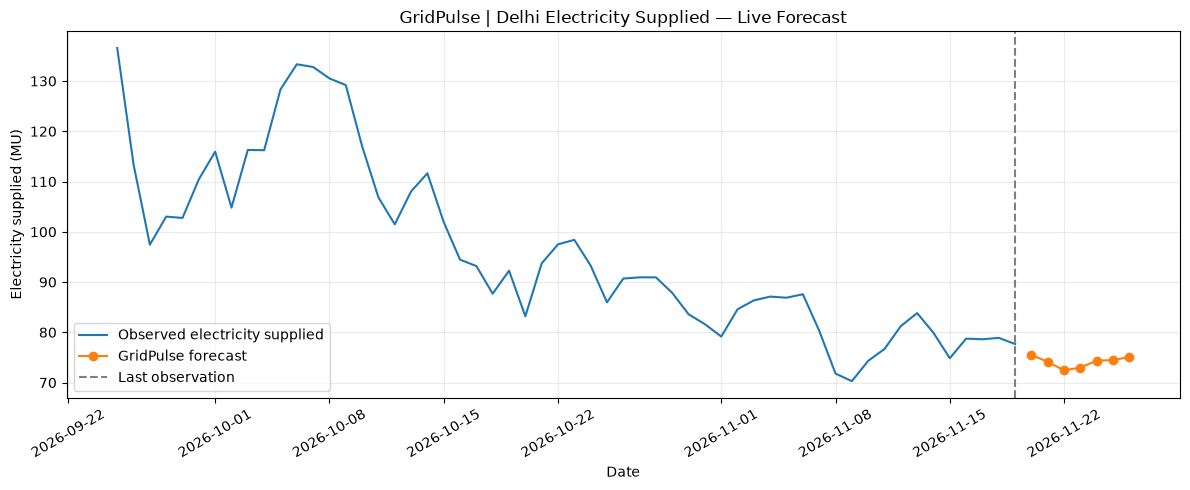

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    recent["date"],
    recent["energy_met_mu"],
    label="Observed electricity supplied",
)

ax.plot(
    pd.to_datetime(forecast_df["date"]),
    forecast_df["ensemble_mu"],
    marker="o",
    label="GridPulse forecast",
)

ax.axvline(
    forecast_origin,
    linestyle="--",
    color="gray",
    label="Last observation",
)

ax.set(
    title="GridPulse | Delhi Electricity Supplied — Live Forecast",
    xlabel="Date",
    ylabel="Electricity supplied (MU)",
)

ax.legend()
ax.grid(alpha=0.25)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 8. Archive the forecast as JSON

In [10]:
import json
from pathlib import Path

output_dir = Path("../data/forecasts")
output_dir.mkdir(parents=True, exist_ok=True)

forecast_record = {
    "issued_at_utc": issued_at.isoformat(),
    "forecast_origin": forecast_origin.date().isoformat(),
    "model_repo": "shishirgarde/gridpulse-ensemble-v1",
    "model_revision": "e2dcdfda9380130aa0c2624f4d7c641f0669c2d8",
    "demand_history_mu": demand_history,
    "weather_forecast": weather_forecast,
    "predictions": live_result["predictions"],
}

file_name = (
    f"gridpulse_{forecast_origin:%Y%m%d}_"
    f"{issued_at:%Y%m%dT%H%M%SZ}.json"
)

output_path = output_dir / file_name

with output_path.open("x", encoding="utf-8") as f:
    json.dump(forecast_record, f, indent=2)

print("Forecast archived:", output_path)

Forecast archived: ..\data\forecasts\gridpulse_20261119_20261120T075717Z.json


## 9. Score archived forecasts once actuals arrive

In [11]:
import json
import pandas as pd
from pathlib import Path

forecast_files = sorted(
    Path("../data/forecasts").glob("gridpulse_*.json")
)

records = []

for path in forecast_files:
    with path.open(encoding="utf-8") as f:
        archive = json.load(f)

    for row in archive["predictions"]:
        records.append({
            "forecast_id": path.stem,
            "issued_at_utc": archive["issued_at_utc"],
            "forecast_origin": archive["forecast_origin"],
            "date": row["date"],
            "horizon": row["horizon"],
            "predicted_mu": row["ensemble_mu"],
        })

monitor = pd.DataFrame(records)

actuals = delhi.rename(
    columns={"energy_met_mu": "actual_mu"}
)[["date", "actual_mu"]].copy()

actuals["date"] = pd.to_datetime(actuals["date"])
monitor["date"] = pd.to_datetime(monitor["date"])

monitor = monitor.merge(actuals, on="date", how="left")

# Only score forecasts issued before their target day began (IST).
issued_ist = pd.to_datetime(
    monitor["issued_at_utc"], utc=True
).dt.tz_convert("Asia/Kolkata")

eligible = issued_ist.dt.date < monitor["date"].dt.date

monitor["error_mu"] = (
    monitor["predicted_mu"] - monitor["actual_mu"]
).where(eligible & monitor["actual_mu"].notna())

print("Archived forecast rows:", len(monitor))
print("Scorable predictions:", monitor["error_mu"].notna().sum())

display(monitor)

Archived forecast rows: 7
Scorable predictions: 0


,forecast_id,issued_at_utc,forecast_origin,date,horizon,predicted_mu,actual_mu,error_mu
0,gridpulse_20261119_20261120T075717Z,2026-11-20T07:57:17.666463+00:00,2026-11-19,2026-11-20,1,75.524200,NaN,NaN
1,gridpulse_20261119_20261120T075717Z,2026-11-20T07:57:17.666463+00:00,2026-11-19,2026-11-21,2,74.120728,NaN,NaN
2,gridpulse_20261119_20261120T075717Z,2026-11-20T07:57:17.666463+00:00,2026-11-19,2026-11-22,3,72.454498,NaN,NaN
3,gridpulse_20261119_20261120T075717Z,2026-11-20T07:57:17.666463+00:00,2026-11-19,2026-11-23,4,72.989334,NaN,NaN
4,gridpulse_20261119_20261120T075717Z,2026-11-20T07:57:17.666463+00:00,2026-11-19,2026-11-24,5,74.358894,NaN,NaN
5,gridpulse_20261119_20261120T075717Z,2026-11-20T07:57:17.666463+00:00,2026-11-19,2026-11-25,6,74.492172,NaN,NaN
6,gridpulse_20261119_20261120T075717Z,2026-11-20T07:57:17.666463+00:00,2026-11-19,2026-11-26,7,75.071930,NaN,NaN


In [12]:
import numpy as np

scored = monitor.dropna(subset=["error_mu"]).copy()

if scored.empty:
    print("No actual observations available for scoring yet.")
else:
    metrics = {
        "n_predictions": len(scored),
        "mae_mu": scored["error_mu"].abs().mean(),
        "rmse_mu": np.sqrt(
            np.mean(scored["error_mu"] ** 2)
        ),
        "bias_mu": scored["error_mu"].mean(),
    }

    print(pd.Series(metrics).round(4))

    display(
        scored.groupby("horizon").agg(
            count=("error_mu", "size"),
            mae_mu=("error_mu", lambda x: x.abs().mean()),
            bias_mu=("error_mu", "mean"),
        ).round(3)
    )

No actual observations available for scoring yet.
